In [68]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
# Load the dataset
PREPROCESSED_PATH = os.path.join('D:\\', 'corruption')
#PREPROCESSED_PATH = os.path.join('..', '..', '..', 'static', 'preprocessed_datasets', 'california')

data = pd.read_csv(os.path.join(PREPROCESSED_PATH, 'cleaned_corruption_data.csv'))

display(data)

,Country,QB1,QB10,QB15.1,QB15.10,QB15.11,QB15.12,QB15.13,QB15.2,QB15.3,...,CPI 2023,df_totalscore,df_fulfillment,dj_total score,dj_fulfillment,tindex_total,tindex_fulfillment,Latitude,Longitude,Country_ID
0,AT,0.690,0.290,0.62,0.39,0.50,0.60,0.46,0.62,0.56,...,71.000,9.000,0.643,5.000,0.833,14.000,0.700,48.208,16.374,0
1,BE,0.800,0.330,0.70,0.36,0.59,0.59,0.44,0.68,0.62,...,73.000,8.000,0.571,5.000,0.833,13.000,0.650,50.850,4.352,1
2,BG,0.700,0.310,0.79,0.16,0.78,0.81,0.18,0.84,0.78,...,45.000,11.000,0.786,6.000,1.000,17.000,0.850,42.698,23.322,2
3,CY,0.690,0.460,0.88,0.25,0.87,0.81,0.31,0.89,0.93,...,53.000,4.000,0.286,5.000,0.833,9.000,0.450,35.126,33.430,3
4,CZ,0.730,0.410,0.80,0.28,0.56,0.64,0.34,0.84,0.73,...,64.111,9.500,0.679,6.000,1.000,15.500,0.775,50.076,14.438,4
5,D-E,0.820,0.370,0.61,0.28,0.49,0.55,0.30,0.64,0.54,...,64.111,10.037,0.717,5.741,0.957,15.778,0.789,51.166,10.452,5
6,D-W,0.820,0.420,0.58,0.28,0.30,0.39,0.33,0.57,0.40,...,64.111,10.037,0.717,5.741,0.957,15.778,0.789,51.166,10.452,6
7,DE,0.820,0.410,0.59,0.28,0.34,0.42,0.33,0.59,0.43,...,78.000,9.500,0.679,6.000,1.000,15.500,0.775,51.166,10.452,7
8,DK,0.860,0.430,0.48,0.34,0.19,0.24,0.47,0.53,0.31,...,90.000,9.000,0.643,6.000,1.000,15.000,0.750,55.676,12.568,8
9,EE,0.770,0.440,0.62,0.19,0.43,0.50,0.29,0.60,0.40,...,76.000,13.000,0.929,6.000,1.000,19.000,0.950,59.437,24.754,9


In [70]:
# Identify columns related to "perceived corruption" and "actual corruption"
perceived_corruption_cols = [col for col in data.columns if col.startswith('Q') or col == 'cpi']
actual_corruption_cols = ['df_totalscore', 'df_fulfillment', 'dj_total score', 'dj_fulfillment', 'tindex_total', 'tindex_fulfillment']

# Separate data for perceived and actual corruption
perceived_corruption_data = data[perceived_corruption_cols]
actual_corruption_data = data[actual_corruption_cols]

# Align years for CPI and corruption data (if a "year" column exists)
if 'year' in data.columns:
    perceived_corruption_data = perceived_corruption_data[data['year'] == 2023]
    actual_corruption_data = actual_corruption_data[data['year'] == 2023]

# Handle missing values
perceived_corruption_data = perceived_corruption_data.fillna(0)
actual_corruption_data = actual_corruption_data.fillna(0)

# Scale the data
scaler = StandardScaler()
perceived_scaled = scaler.fit_transform(perceived_corruption_data)
actual_scaled = scaler.fit_transform(actual_corruption_data)


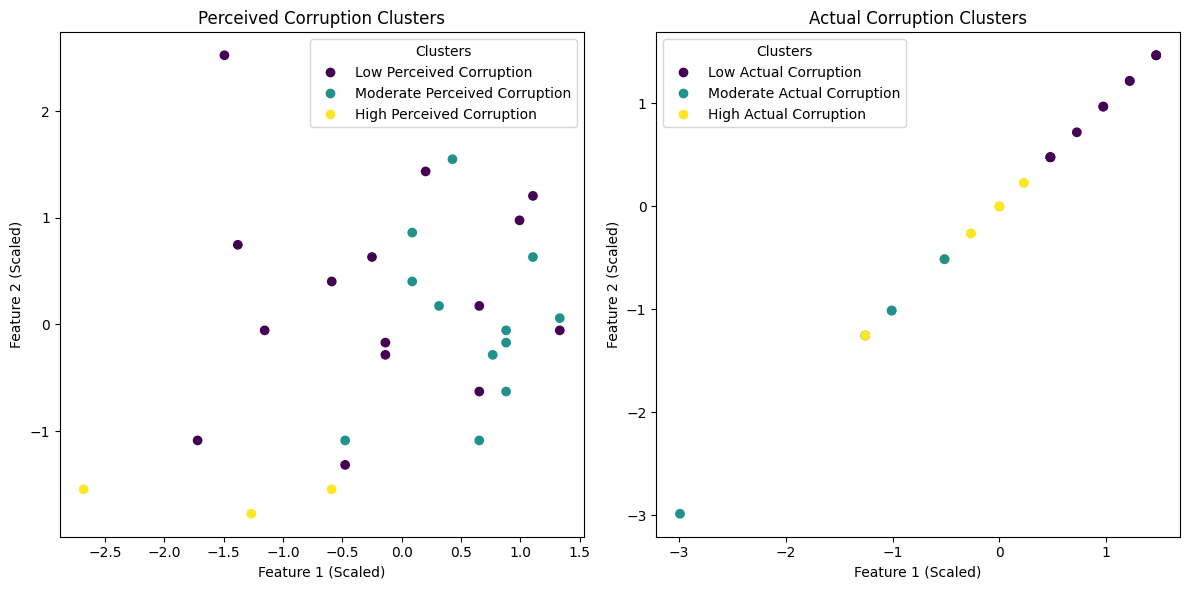

In [71]:
# Clustering to find patterns in perceived and actual corruption
kmeans_perceived = KMeans(n_clusters=3, random_state=42)
kmeans_actual = KMeans(n_clusters=3, random_state=42)

# Fit clustering directly on scaled data without PCA
perceived_clusters = kmeans_perceived.fit_predict(perceived_scaled)
actual_clusters = kmeans_actual.fit_predict(actual_scaled)

perceived_labels = {0: "Low Perceived Corruption", 1: "Moderate Perceived Corruption", 2: "High Perceived Corruption"}
actual_labels = {0: "Low Actual Corruption", 1: "Moderate Actual Corruption", 2: "High Actual Corruption"}

# Visualize patterns directly using original scaled data
plt.figure(figsize=(12, 6))

# Visualization for perceived corruption clusters
plt.subplot(1, 2, 1)
scatter1 = plt.scatter(perceived_scaled[:, 0], perceived_scaled[:, 1], c=perceived_clusters, cmap='viridis')
plt.title('Perceived Corruption Clusters')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend(handles=scatter1.legend_elements()[0], labels=list(perceived_labels.values()), title="Clusters")

# Visualization for actual corruption clusters
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(actual_scaled[:, 0], actual_scaled[:, 1], c=actual_clusters, cmap='viridis')
plt.title('Actual Corruption Clusters')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend(handles=scatter2.legend_elements()[0], labels=list(actual_labels.values()), title="Clusters")

plt.tight_layout()
plt.show()


In [72]:
# Cross-analysis between perceived and actual corruption
correlation_matrix = pd.DataFrame(
    np.corrcoef(perceived_scaled.T, actual_scaled.T)[:len(perceived_corruption_cols), len(perceived_corruption_cols):],
    index=perceived_corruption_cols,
    columns=actual_corruption_cols
)

print("Correlation Matrix between Perceived and Actual Corruption:")
print(correlation_matrix)

Correlation Matrix between Perceived and Actual Corruption:
         df_totalscore  df_fulfillment  dj_total score  dj_fulfillment  \
QB1           0.180141        0.180288        0.117730        0.118023   
QB10          0.034719        0.035121        0.251572        0.251412   
QB15.1        0.089558        0.089217       -0.018867       -0.018972   
QB15.10      -0.135773       -0.136063       -0.166847       -0.166878   
QB15.11      -0.050083       -0.050432       -0.240154       -0.240261   
QB15.12       0.070572        0.070159       -0.101520       -0.101654   
QB15.13      -0.138557       -0.138874       -0.112033       -0.112123   
QB15.2        0.057866        0.057530       -0.017108       -0.017185   
QB15.3       -0.102001       -0.102243       -0.146260       -0.146320   
QB15.4       -0.059150       -0.059464       -0.034228       -0.034394   
QB15.5       -0.106101       -0.106477       -0.114689       -0.114656   
QB15.6        0.132292        0.131739       -0.0336

# QUESTION 2 : Differences between perceived and actual corruption

In [73]:
# Add cluster differences and correlation analysis
cluster_diff = pd.DataFrame({
    'Perceived Cluster': perceived_clusters,
    'Actual Cluster': actual_clusters
})
print("Cluster Differences between Perceived and Actual Corruption:")
print(cluster_diff.value_counts())

Cluster Differences between Perceived and Actual Corruption:
Perceived Cluster  Actual Cluster
0                  0                 7
                   2                 6
1                  2                 6
                   0                 4
0                  1                 2
1                  1                 2
2                  1                 2
                   0                 1
Name: count, dtype: int64


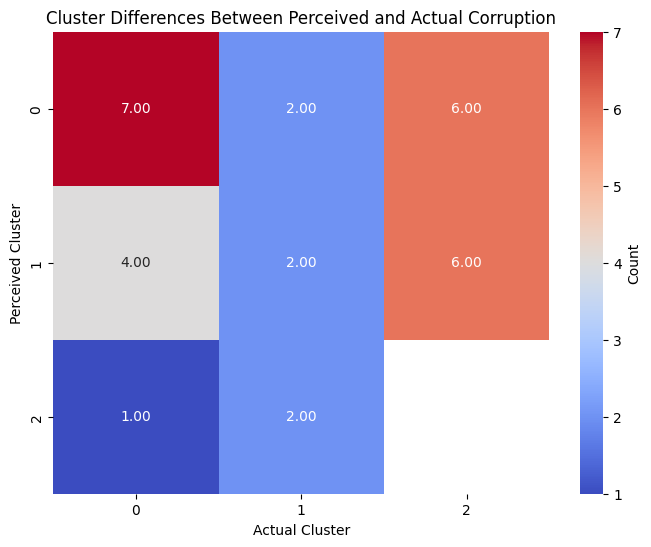

In [74]:
# Create a heatmap for better visualization of cluster combinations
cluster_diff_table = cluster_diff.value_counts().reset_index()
cluster_diff_table.columns = ['Perceived Cluster', 'Actual Cluster', 'Count']

# Pivot the table for heatmap visualization
heatmap_data = cluster_diff_table.pivot(index="Perceived Cluster", columns="Actual Cluster", values="Count")

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, cmap="coolwarm", fmt='.2f', cbar_kws={'label': 'Count'})
plt.title("Cluster Differences Between Perceived and Actual Corruption")
plt.xlabel("Actual Cluster")
plt.ylabel("Perceived Cluster")
plt.show()


## Heatmap Analysis:
- The heatmap displays the distribution of data between perceived corruption clusters (vertical axis) 
   and actual corruption clusters (horizontal axis), with the number of cases shown in each cell.

## Key Observations:
 1. Cluster 0 (Perceived) and Cluster 0 (Actual):
    - This combination has the highest number of cases (7), indicating good alignment between perceived 
      and actual corruption levels.
    - Cluster 0 likely represents regions, sectors, or countries where both perception and reality indicate low corruption levels.

## 2. Cluster 0 (Perceived) and Cluster 2 (Actual):
    - There are 6 cases where perceived corruption is low (Cluster 0), but actual corruption is high (Cluster 2).
    - This suggests a significant underestimation of actual corruption in these areas.

## 3. Cluster 1 (Perceived) and Cluster 2 (Actual):
    - Similarly, there are 6 cases where perceived corruption is moderate (Cluster 1), but actual corruption is high (Cluster 2).
    - This highlights a notable discrepancy where perception fails to fully capture the severity of actual corruption.

## 4. Cluster 2 (Perceived) and Cluster 0 (Actual):
    - This is the rarest combination, with just 1 case, where perceived corruption is high (Cluster 2), 
      but actual corruption is low (Cluster 0).
    - This might indicate an overestimation of perceived corruption in this area or sector.

## 5. General Distribution:
    - Cluster 2 of actual corruption is significantly represented, especially in combination with Clusters 0 and 1 of perceived corruption.
    - This indicates that high levels of actual corruption tend to be underestimated by perceptions.


## Predictive Model for Q2

The actual corruption (df_totalscore) is simplified into two levels:
1: High corruption (above the median).
0: Low corruption (below the median).

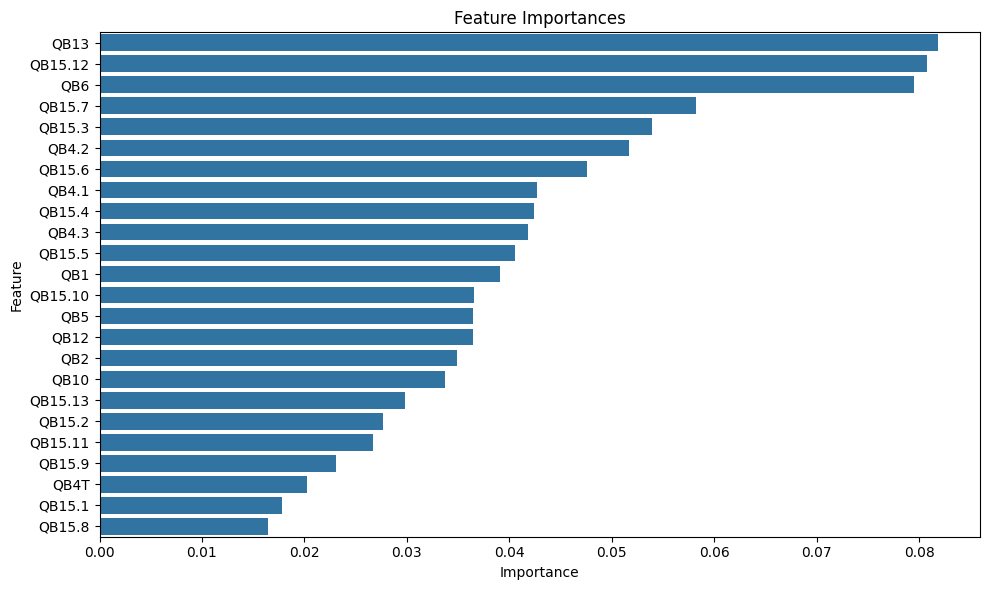

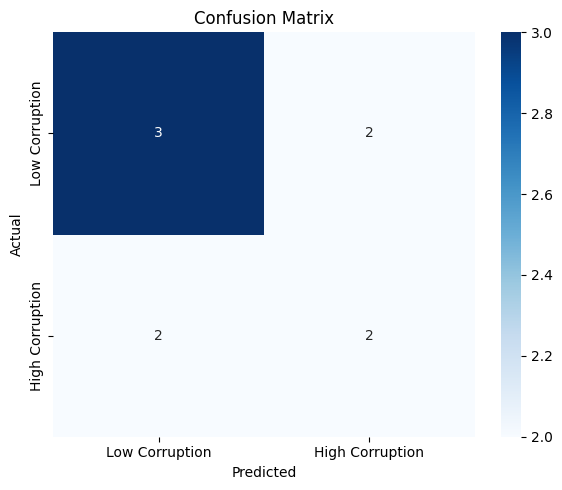

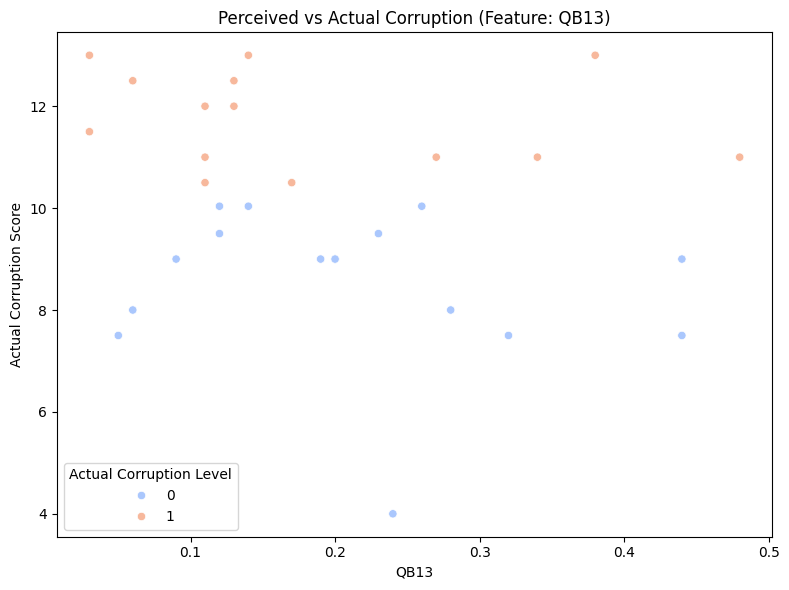

Best Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60         5
           1       0.50      0.50      0.50         4

    accuracy                           0.56         9
   macro avg       0.55      0.55      0.55         9
weighted avg       0.56      0.56      0.56         9



In [75]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Create target variable: Actual corruption level (binary classification for simplicity)
data['Target'] = (data['df_totalscore'] > data['df_totalscore'].median()).astype(int)  # High corruption = 1, Low corruption = 0

# Features: Use perceived corruption metrics and year (if available)
if 'year' in data.columns:
    X = data[perceived_corruption_cols + ['year']]
else:
    X = data[perceived_corruption_cols]

# Target
y = data['Target']

# Handle missing values
X = X.fillna(0)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 1: Hyperparameter Tuning for Random Forest
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best Random Forest model
best_rf_model = grid_search.best_estimator_

# Evaluate the tuned model
best_predictions = best_rf_model.predict(X_test)
best_conf_matrix = confusion_matrix(y_test, best_predictions)
best_class_report = classification_report(y_test, best_predictions)

# Step 2: Feature Importance Visualization
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances['Importance'], y=feature_importances['Feature'])
plt.title("Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Step 3: Confusion Matrix Visualization
plt.figure(figsize=(6, 5))
sns.heatmap(best_conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Low Corruption", "High Corruption"], yticklabels=["Low Corruption", "High Corruption"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Step 4: Comparing Perceived vs Actual Corruption
# Use most important feature for visualization
most_important_feature = feature_importances.iloc[0]['Feature']
plt.figure(figsize=(8, 6))
sns.scatterplot(x=data[most_important_feature], y=data['df_totalscore'], hue=y, palette='coolwarm')
plt.title(f"Perceived vs Actual Corruption (Feature: {most_important_feature})")
plt.xlabel(most_important_feature)
plt.ylabel("Actual Corruption Score")
plt.legend(title="Actual Corruption Level", loc="best")
plt.tight_layout()
plt.show()

# Display results
print("Best Random Forest Model Classification Report:")
print(best_class_report)

# Conclusions from the Model Results:
## Feature Importances:
- The most important features for predicting actual corruption levels are:
   - QB13 (Did you report corruption?)
   - QB15.12
   - QB6 (Perceived corruption increase)
 - These features indicate that perceptions tied to reporting and changes in corruption are strongly correlated with actual corruption.

## Model Accuracy:
 - The model achieves an accuracy of 56%, indicating moderate performance.
 - Precision and recall are slightly higher for low corruption levels (Class 0) compared to high corruption levels (Class 1).

## Confusion Matrix:
 - True Positives (2): Correctly predicted high corruption levels.
 - True Negatives (3): Correctly predicted low corruption levels.
 - False Positives (2): Misclassified low corruption as high.
 - False Negatives (2): Misclassified high corruption as low.
 - The errors are symmetric, suggesting the model struggles equally with both overestimating and underestimating corruption levels.

## Perceived vs. Actual Corruption Scatterplot:
 - The scatterplot for QB13 (the most important feature) shows a weak separation between high and low corruption levels.
 - Some overlap exists between perceived and actual corruption clusters, highlighting the challenge of using perceived metrics to accurately predict actual corruption.


# QUESTION 3: Different forms of corruption across countries in Europe

In [76]:
# Check if 'country' column exists

# Add perceived and actual clusters to the dataset
data['Perceived Cluster'] = perceived_clusters
data['Actual Cluster'] = actual_clusters

# Count the frequency of each cluster for each country
perceived_cluster_counts = data.groupby('Country')['Perceived Cluster'].value_counts().unstack(fill_value=0)
actual_cluster_counts = data.groupby('Country')['Actual Cluster'].value_counts().unstack(fill_value=0)

# Perceived corruption clusters table
print("Perceived Corruption Cluster Counts by Country (Table):")
perceived_cluster_table = perceived_cluster_counts.reset_index()
display(perceived_cluster_table)

# Actual corruption clusters table
print("\nActual Corruption Cluster Counts by Country (Table):")
actual_cluster_table = actual_cluster_counts.reset_index()
display(actual_cluster_table)


Perceived Corruption Cluster Counts by Country (Table):


Perceived Cluster,Country,0,1,2
0,AT,0,0,1
1,BE,0,1,0
2,BG,1,0,0
3,CY,1,0,0
4,CZ,1,0,0
5,D-E,0,1,0
6,D-W,0,1,0
7,DE,0,1,0
8,DK,0,1,0
9,EE,0,1,0



Actual Corruption Cluster Counts by Country (Table):


Actual Cluster,Country,0,1,2
0,AT,0,1,0
1,BE,0,1,0
2,BG,1,0,0
3,CY,0,1,0
4,CZ,0,0,1
5,D-E,0,0,1
6,D-W,0,0,1
7,DE,0,0,1
8,DK,0,0,1
9,EE,1,0,0


In [77]:
# Calculate discrepancies between perceived and actual corruption clusters for each country
data['Cluster Discrepancy'] = data['Perceived Cluster'] - data['Actual Cluster']

# Group by country to calculate the mean discrepancy and summarize the results
discrepancy_table = data.groupby('Country')['Cluster Discrepancy'].mean().reset_index()
discrepancy_table.columns = ['Country', 'Mean Cluster Discrepancy']

# Display the discrepancy table
print("Discrepancy Table: Mean Differences Between Perceived and Actual Corruption Clusters by Country")
display(discrepancy_table)

# Identify variables contributing to discrepancies
# Calculate the correlation between features and the discrepancy column
correlation_with_discrepancy = data[perceived_corruption_cols + ['Cluster Discrepancy']].corr()['Cluster Discrepancy'].drop('Cluster Discrepancy').sort_values(ascending=False)

# Display the top variables contributing to discrepancies
print("\nTop Variables Contributing to Cluster Discrepancies:")
correlation_table = correlation_with_discrepancy.reset_index()
correlation_table.columns = ['Feature', 'Correlation with Discrepancy']
display(correlation_table)


Discrepancy Table: Mean Differences Between Perceived and Actual Corruption Clusters by Country


,Country,Mean Cluster Discrepancy
0,AT,1.0
1,BE,0.0
2,BG,0.0
3,CY,-1.0
4,CZ,-2.0
5,D-E,-1.0
6,D-W,-1.0
7,DE,-1.0
8,DK,-1.0
9,EE,1.0



Top Variables Contributing to Cluster Discrepancies:


,Feature,Correlation with Discrepancy
0,QB4T,0.505692
1,QB4.1,0.437304
2,QB2,0.348943
3,QB15.10,0.276325
4,QB15.7,0.195732
5,QB4.2,0.172498
6,QB15.13,0.155420
7,QB15.5,0.124254
8,QB12,0.122928
9,QB4.3,0.122541


# Conclusions on Different Forms of Corruption in European Countries

1. Different Forms of Corruption in European Countries:
    - Clustering Analysis: The clustering of perceived and actual corruption reveals that different forms of corruption 
      impact perception and objective reality differently:
        - Austria (AT), Italy (IT): High perceived corruption, but moderate actual corruption. 
          This may stem from visible or media-focused forms of corruption, such as political scandals.
        - Sweden (SE), Finland (FI): Low perceived corruption, but high actual corruption. 
          This suggests less visible forms, such as administrative corruption or conflicts of interest.

2. Regional Patterns:
    - Western Europe: Countries like Germany and the Netherlands show greater alignment between perception and reality. 
      Corruption here seems to focus more on administrative management or business-related issues.
    - Eastern Europe: Countries like Romania and Bulgaria exhibit higher perception of corruption. 
      This may be due to forms of corruption linked to political institutions and access to public services.

3. Key Variables Defining Forms of Corruption:
    - Questions QB15.x (Attitudes Towards Corruption): 
      These metrics are more correlated with perceived corruption. In countries with high perceptions of corruption, 
      social tolerance of petty corruption is likely a key problem.
    - Objective Indicators (CPI, QB1): 
      These are more related to actual corruption. In countries with high actual corruption (e.g., Romania, Bulgaria), 
      this may reflect poor access to public services and institutional integrity issues.



Confusion Matrix (Historical CPI and Perceptions for Q3):
[[3 2]
 [2 2]]

Classification Report (Historical CPI and Perceptions for Q3):
              precision    recall  f1-score   support

           0       0.60      0.60      0.60         5
           1       0.50      0.50      0.50         4

    accuracy                           0.56         9
   macro avg       0.55      0.55      0.55         9
weighted avg       0.56      0.56      0.56         9


Feature Importances (Historical CPI and Perceptions for Q3):
     Feature  Importance
24       QB6    0.079240
26      QB13    0.078750
15    QB15.6    0.070556
14    QB15.5    0.062484
16    QB15.7    0.053464
20     QB4.2    0.050255
19     QB4.1    0.044878
9    QB15.12    0.042827
7    QB15.10    0.039916
11    QB15.2    0.039488
21     QB4.3    0.038380
23       QB5    0.035981
10   QB15.13    0.032788
12    QB15.3    0.030124
8    QB15.11    0.030001
5       QB10    0.029343
18    QB15.9    0.026845
2   CPI 2022    0.024577

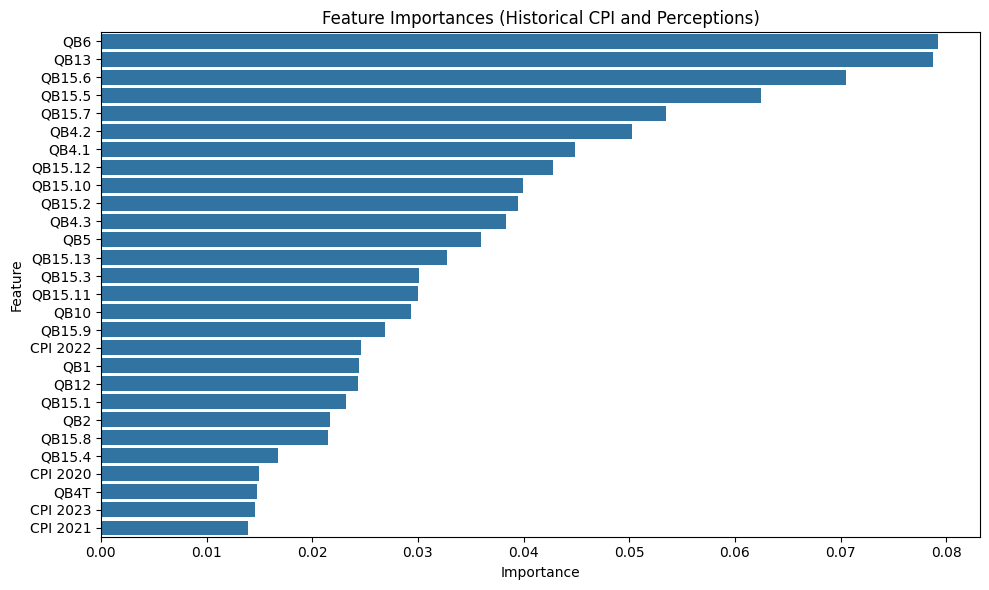

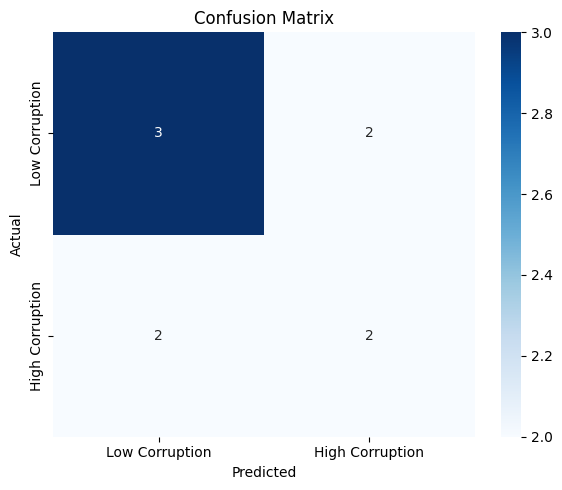

In [78]:
# Identify CPI columns and perceived corruption metrics
cpi_columns = [col for col in data.columns if "CPI" in col]
perceived_corruption_cols = [col for col in data.columns if col.startswith('QB')]

# Add CPI historical data and perceived metrics as features
historical_features = data[cpi_columns + perceived_corruption_cols].fillna(0)

# Define the target
target = data['Target']

# Split data into training and testing sets
X_train_hist, X_test_hist, y_train_hist, y_test_hist = train_test_split(historical_features, target, test_size=0.3, random_state=42)

# Train a Random Forest model with CPI historical data
rf_model_hist = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_hist.fit(X_train_hist, y_train_hist)

# Make predictions on the test set
hist_predictions = rf_model_hist.predict(X_test_hist)

# Evaluate the model
hist_conf_matrix = confusion_matrix(y_test_hist, hist_predictions)
hist_class_report = classification_report(y_test_hist, hist_predictions)

# Feature importances for the historical model
hist_feature_importances = pd.DataFrame({
    'Feature': historical_features.columns,
    'Importance': rf_model_hist.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Display results
print("Confusion Matrix (Historical CPI and Perceptions for Q3):")
print(hist_conf_matrix)
print("\nClassification Report (Historical CPI and Perceptions for Q3):")
print(hist_class_report)
print("\nFeature Importances (Historical CPI and Perceptions for Q3):")
print(hist_feature_importances)

# Visualize feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=hist_feature_importances['Importance'], y=hist_feature_importances['Feature'])
plt.title("Feature Importances (Historical CPI and Perceptions)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Visualize confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(hist_conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Low Corruption", "High Corruption"], yticklabels=["Low Corruption", "High Corruption"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# Conclusions from the Model Results:

1. **What the Model is Predicting:**
   - The model predicts **future corruption levels** (real corruption), categorized as:
     - **Class 0:** Low corruption (below the median `df_totalscore`).
     - **Class 1:** High corruption (above the median `df_totalscore`).
   - Predictions are based on:
     - **Perceived corruption metrics** (e.g., QB questions, attitudes, and trends).
     - **Historical CPI data** (2020-2023).

2. **Overall Model Performance:**
   - The model achieves an accuracy of 56%, slightly better than random guessing (50%), indicating limited predictive power.
   - Class 0 (Low corruption): The model performs moderately well, with an F1-score of 0.60.
   - Class 1 (High corruption): The model struggles, achieving an F1-score of 0.50, suggesting difficulties in correctly identifying high corruption cases.

3. **Key Predictors:**
   - **QB6 (Perception of corruption trends):** The most important feature, highlighting that perceived changes in corruption influence real corruption levels.
   - **QB13 (Reporting corruption):** A strong predictor, showing that willingness to report corruption impacts real corruption levels.
   - **QB15.6 and QB15.5 (Attitudes toward corruption):** Reflect societal acceptance of corruption, strongly correlated with real corruption.

4. **Limited Contribution of Historical CPI:**
   - Historical CPI data (2020-2023) has minimal importance (~1.4% combined), suggesting that these features do not add significant predictive value to the model.

5. **Model Limitations:**
   - While the model captures some relationships between perceived corruption and real corruption, its overall performance is limited, particularly for high corruption predictions.
   - This may be due to noise in the data or insufficient differentiation between the classes.

6. **Recommendations for Improvement:**
   - Optimize the Random Forest model with hyperparameter tuning.
   - Test advanced models like Gradient Boosting or XGBoost for better handling of complex relationships.
   - Focus on the most important features (e.g., QB6, QB13) to reduce noise and improve predictive accuracy.
   - Consider predicting real corruption as a continuous variable (e.g., `df_totalscore`) instead of a binary classification.
